Distance Matrix:


,DC,C1,C2,C3,C4,C5,C6,C7,C8,C9
DC,0.00,52.61,35.61,35.36,72.80,57.97,80.80,72.03,71.59,88.02
C1,52.61,0.00,27.78,63.07,36.50,60.61,57.14,83.74,19.31,76.66
C2,35.61,27.78,0.00,35.47,37.20,36.40,47.42,58.31,42.58,60.13
C3,35.36,63.07,35.47,0.00,63.64,29.00,60.90,37.12,77.62,59.82
C4,72.80,36.50,37.20,63.64,0.00,44.64,23.26,66.21,31.38,46.04
C5,57.97,60.61,36.40,29.00,44.64,0.00,34.21,23.35,68.60,31.06
C6,80.80,57.14,47.42,60.90,23.26,34.21,0.00,50.49,54.63,23.35
C7,72.03,83.74,58.31,37.12,66.21,23.35,50.49,0.00,91.83,35.44
C8,71.59,19.31,42.58,77.62,31.38,68.60,54.63,91.83,0.00,77.03
C9,88.02,76.66,60.13,59.82,46.04,31.06,23.35,35.44,77.03,0.00


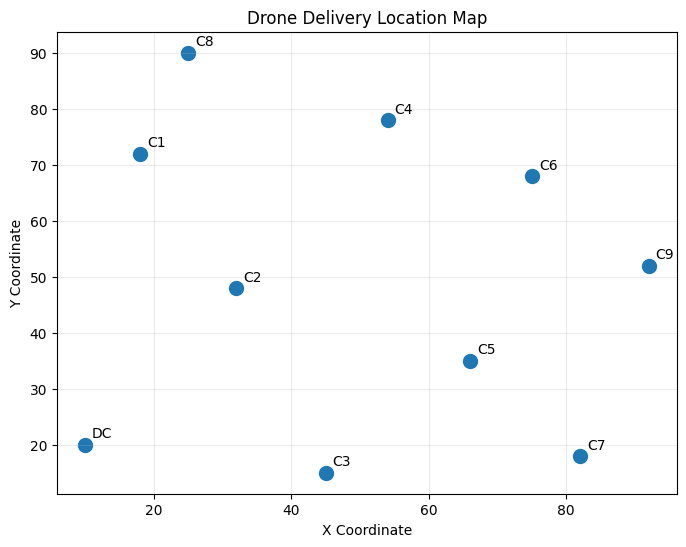

In [ ]:
import heapq
import math
import random
import time
import tracemalloc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Drone delivery locations
LOCATION_NAMES = [
    "DC", "C1", "C2", "C3", "C4",
    "C5", "C6", "C7", "C8", "C9"
]

# Coordinates of distribution center and customer locations
COORDS = {
    "DC": (10, 20),
    "C1": (18, 72),
    "C2": (32, 48),
    "C3": (45, 15),
    "C4": (54, 78),
    "C5": (66, 35),
    "C6": (75, 68),
    "C7": (82, 18),
    "C8": (25, 90),
    "C9": (92, 52)
}


def build_distance_matrix(locations):
    n = len(locations)
    d = np.zeros((n, n), dtype=float)

    for i in range(n):
        for j in range(n):
            if i != j:
                x1, y1 = COORDS[locations[i]]
                x2, y2 = COORDS[locations[j]]

                d[i, j] = round(
                    math.hypot(x1 - x2, y1 - y2), 2
                )

    return d


DIST = build_distance_matrix(LOCATION_NAMES)


def tour_cost(route, dist=DIST):
    if not route:
        return 0.0

    return float(
        sum(
            dist[route[i], route[(i + 1) % len(route)]]
            for i in range(len(route))
        )
    )


def route_text(route, locations=LOCATION_NAMES):
    if route is None:
        return "No route"

    return " -> ".join(
        locations[i] for i in route + [route[0]]
    )


def show_problem():
    df = pd.DataFrame(
        DIST,
        index=LOCATION_NAMES,
        columns=LOCATION_NAMES
    )

    print("Distance Matrix:")
    display(df)

    plt.figure(figsize=(8, 6))

    xs = [COORDS[x][0] for x in LOCATION_NAMES]
    ys = [COORDS[x][1] for x in LOCATION_NAMES]

    plt.scatter(xs, ys, s=100)

    for location, (x, y) in COORDS.items():
        plt.annotate(
            location,
            (x, y),
            xytext=(5, 5),
            textcoords="offset points"
        )

    plt.title("Drone Delivery Location Map")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.grid(alpha=0.25)
    plt.show()


show_problem()

In [ ]:
#uninformed search

In [ ]:
def bfs_drone(dist, start=0):
    n = len(dist)

    queue = deque([
        (start, (start,), 0.0)
    ])

    expanded = 0
    best_route = None
    best_cost = float("inf")

    while queue:

        current, path, cost = queue.popleft()
        expanded += 1

        if len(path) == n:

            total = cost + dist[current, start]

            if total < best_cost:
                best_cost = total
                best_route = list(path)

            continue

        for nxt in range(n):

            if nxt not in path:

                queue.append(
                    (
                        nxt,
                        path + (nxt,),
                        cost + dist[current, nxt]
                    )
                )

    return best_route, best_cost, expanded

In [ ]:
def dfs_drone(dist, start=0):
    n = len(dist)

    stack = [
        (start, (start,), 0.0)
    ]

    expanded = 0
    best_route = None
    best_cost = float("inf")

    while stack:

        current, path, cost = stack.pop()
        expanded += 1

        if len(path) == n:

            total = cost + dist[current, start]

            if total < best_cost:
                best_cost = total
                best_route = list(path)

            continue

        for nxt in reversed(range(n)):

            if nxt not in path:

                stack.append(
                    (
                        nxt,
                        path + (nxt,),
                        cost + dist[current, nxt]
                    )
                )

    return best_route, best_cost, expanded

In [ ]:
#uniform cost search
def ucs_drone(dist, start=0):
    n = len(dist)

    pq = [
        (0.0, start, (start,))
    ]

    expanded = 0
    best_route = None
    best_cost = float("inf")

    while pq:

        cost, current, path = heapq.heappop(pq)
        expanded += 1

        if len(path) == n:

            total = cost + dist[current, start]

            if total < best_cost:
                best_cost = total
                best_route = list(path)

            continue

        for nxt in range(n):

            if nxt not in path:

                heapq.heappush(
                    pq,
                    (
                        cost + dist[current, nxt],
                        nxt,
                        path + (nxt,)
                    )
                )

    return best_route, best_cost, expanded

In [ ]:
#Informed Search
#MST Lower Bound
def mst_cost(nodes, dist):
    nodes = list(nodes)

    if len(nodes) <= 1:
        return 0.0

    in_tree = {nodes[0]}
    total = 0.0

    while len(in_tree) < len(nodes):

        best = float("inf")
        pick = None

        for u in in_tree:

            for v in nodes:

                if v not in in_tree and dist[u, v] < best:

                    best = dist[u, v]
                    pick = v

        total += best
        in_tree.add(pick)

    return total


def drone_lower_bound(current, unvisited, start, dist):

    unvisited = set(unvisited)

    if not unvisited:
        return dist[current, start]

    mst = mst_cost(unvisited, dist)

    to_unvisited = min(
        dist[current, u]
        for u in unvisited
    )

    to_start = min(
        dist[u, start]
        for u in unvisited
    )

    return mst + to_unvisited + to_start

In [ ]:
#Greedy Best-First Search
def greedy_drone(dist, start=0):

    n = len(dist)

    pq = []

    h0 = drone_lower_bound(
        start,
        range(1, n),
        start,
        dist
    )

    heapq.heappush(
        pq,
        (h0, start, (start,), 0.0)
    )

    expanded = 0

    while pq:

        _, current, path, g = heapq.heappop(pq)

        expanded += 1

        if len(path) == n:

            return (
                list(path),
                g + dist[current, start],
                expanded
            )

        unvisited = [
            x for x in range(n)
            if x not in path
        ]

        for nxt in unvisited:

            new_path = path + (nxt,)

            remaining = [
                x for x in range(n)
                if x not in new_path
            ]

            h = drone_lower_bound(
                nxt,
                remaining,
                start,
                dist
            )

            heapq.heappush(
                pq,
                (
                    h,
                    nxt,
                    new_path,
                    g + dist[current, nxt]
                )
            )

    return None, float("inf"), expanded

In [ ]:
#A*
def astar_drone(dist, start=0):

    n = len(dist)

    pq = []

    h0 = drone_lower_bound(
        start,
        range(1, n),
        start,
        dist
    )

    heapq.heappush(
        pq,
        (h0, 0.0, start, (start,))
    )

    expanded = 0

    while pq:

        f, g, current, path = heapq.heappop(pq)

        expanded += 1

        if len(path) == n:

            return (
                list(path),
                g + dist[current, start],
                expanded
            )

        for nxt in range(n):

            if nxt not in path:

                new_g = (
                    g + dist[current, nxt]
                )

                new_path = path + (nxt,)

                remaining = [
                    x for x in range(n)
                    if x not in new_path
                ]

                h = drone_lower_bound(
                    nxt,
                    remaining,
                    start,
                    dist
                )

                heapq.heappush(
                    pq,
                    (
                        new_g + h,
                        new_g,
                        nxt,
                        new_path
                    )
                )

    return None, float("inf"), expanded

In [ ]:
def hill_climbing_drone(
    dist,
    start=0,
    restarts=30,
    max_iter=1000
):

    n = len(dist)

    best_global_route = None
    best_global_cost = float("inf")

    total_iterations = 0
    successful_restarts = 0

    base = list(range(n))
    base.remove(start)

    for _ in range(restarts):

        current = [
            start
        ] + random.sample(
            base,
            len(base)
        )

        current_cost = tour_cost(
            current,
            dist
        )

        improved = False

        for _ in range(max_iter):

            total_iterations += 1

            best_neighbor = current
            best_neighbor_cost = current_cost

            for i in range(1, n - 1):

                for j in range(i + 1, n):

                    neighbor = current[:]

                    neighbor[i], neighbor[j] = (
                        neighbor[j],
                        neighbor[i]
                    )

                    cost = tour_cost(
                        neighbor,
                        dist
                    )

                    if cost < best_neighbor_cost:

                        best_neighbor = neighbor
                        best_neighbor_cost = cost

            if best_neighbor_cost >= current_cost:
                break

            current = best_neighbor
            current_cost = best_neighbor_cost
            improved = True

        if improved:
            successful_restarts += 1

        if current_cost < best_global_cost:

            best_global_route = current[:]
            best_global_cost = current_cost

    return (
        best_global_route,
        best_global_cost,
        total_iterations,
        successful_restarts
    )

In [ ]:
def hill_climbing_drone(
    dist,
    start=0,
    restarts=30,
    max_iter=1000
):

    n = len(dist)

    best_global_route = None
    best_global_cost = float("inf")

    total_iterations = 0
    successful_restarts = 0

    base = list(range(n))
    base.remove(start)

    for _ in range(restarts):

        current = [
            start
        ] + random.sample(
            base,
            len(base)
        )

        current_cost = tour_cost(
            current,
            dist
        )

        improved = False

        for _ in range(max_iter):

            total_iterations += 1

            best_neighbor = current
            best_neighbor_cost = current_cost

            for i in range(1, n - 1):

                for j in range(i + 1, n):

                    neighbor = current[:]

                    neighbor[i], neighbor[j] = (
                        neighbor[j],
                        neighbor[i]
                    )

                    cost = tour_cost(
                        neighbor,
                        dist
                    )

                    if cost < best_neighbor_cost:

                        best_neighbor = neighbor
                        best_neighbor_cost = cost

            if best_neighbor_cost >= current_cost:
                break

            current = best_neighbor
            current_cost = best_neighbor_cost
            improved = True

        if improved:
            successful_restarts += 1

        if current_cost < best_global_cost:

            best_global_route = current[:]
            best_global_cost = current_cost

    return (
        best_global_route,
        best_global_cost,
        total_iterations,
        successful_restarts
    )

In [ ]:
def backtracking_csp_drone(dist, start=0):

    n = len(dist)

    best_route = None
    best_cost = float("inf")
    expanded = 0

    def search(path, remaining, cost):

        nonlocal best_route
        nonlocal best_cost
        nonlocal expanded

        expanded += 1

        if not remaining:

            total = (
                cost
                + dist[path[-1], start]
            )

            if total < best_cost:

                best_cost = total
                best_route = path[:]

            return

        candidates = sorted(
            remaining,
            key=lambda x: dist[path[-1], x]
        )

        for nxt in candidates:

            new_cost = (
                cost
                + dist[path[-1], nxt]
            )

            if new_cost < best_cost:

                search(
                    path + [nxt],
                    remaining - {nxt},
                    new_cost
                )

    search(
        [start],
        set(range(n)) - {start},
        0.0
    )

    return (
        best_route,
        best_cost,
        expanded
    )

In [ ]:
def branch_and_bound_drone(dist, start=0):

    n = len(dist)

    best_route = None
    best_cost = float("inf")
    expanded = 0

    def search(path, remaining, cost):

        nonlocal best_route
        nonlocal best_cost
        nonlocal expanded

        expanded += 1

        if not remaining:

            total = (
                cost
                + dist[path[-1], start]
            )

            if total < best_cost:

                best_cost = total
                best_route = path[:]

            return

        lower_bound = (
            cost
            + drone_lower_bound(
                path[-1],
                remaining,
                start,
                dist
            )
        )

        if lower_bound >= best_cost:
            return

        candidates = sorted(
            remaining,
            key=lambda x: dist[path[-1], x]
        )

        for nxt in candidates:

            new_cost = (
                cost
                + dist[path[-1], nxt]
            )

            if new_cost < best_cost:

                search(
                    path + [nxt],
                    remaining - {nxt},
                    new_cost
                )

    search(
        [start],
        set(range(n)) - {start},
        0.0
    )

    return (
        best_route,
        best_cost,
        expanded
    )

In [ ]:
# ============================================================
# GENETIC ALGORITHM - DRONE DELIVERY
# ============================================================

def genetic_algorithm_drone(
    dist,
    start=0,
    population_size=80,
    generations=300,
    mutation_rate=0.08,
    elite_size=4
):

    n = len(dist)

    # Customer nodes excluding distribution center
    nodes = [
        i for i in range(n)
        if i != start
    ]


    # -------------------------
    # Create random route
    # -------------------------
    def create_route():

        route = [start]

        route += random.sample(
            nodes,
            len(nodes)
        )

        return route


    # -------------------------
    # Calculate fitness
    # -------------------------
    def fitness(route):

        cost = tour_cost(
            route,
            dist
        )

        return 1 / (cost + 1e-10)


    # -------------------------
    # Ordered Crossover
    # -------------------------
    def crossover(parent1, parent2):

        child = [None] * n

        child[0] = start

        left, right = sorted(
            random.sample(
                range(1, n),
                2
            )
        )

        # Copy section from parent 1
        child[left:right] = parent1[left:right]

        used = set(
            x for x in child
            if x is not None
        )

        # Fill remaining positions using parent 2
        remaining = [
            x for x in parent2
            if x not in used
        ]

        index = 0

        for i in range(1, n):

            if child[i] is None:

                child[i] = remaining[index]

                index += 1

        return child


    # -------------------------
    # Mutation
    # -------------------------
    def mutate(route):

        if random.random() < mutation_rate:

            i, j = random.sample(
                range(1, n),
                2
            )

            route[i], route[j] = (
                route[j],
                route[i]
            )


    # -------------------------
    # Initial population
    # -------------------------
    population = [
        create_route()
        for _ in range(
            population_size
        )
    ]


    # Best solution
    best_route = min(
        population,
        key=lambda route:
            tour_cost(
                route,
                dist
            )
    )


    best_cost = tour_cost(
        best_route,
        dist
    )


    # Store convergence history
    history = [
        best_cost
    ]


    # ========================================================
    # GENERATIONS
    # ========================================================

    for generation in range(
        generations
    ):

        # Calculate fitness
        fitness_values = [
            fitness(route)
            for route in population
        ]


        # Sort population according to fitness
        ranked_population = sorted(
            population,
            key=lambda route:
                fitness(route),
            reverse=True
        )


        # Keep elite solutions
        new_population = [
            route[:]
            for route in
            ranked_population[
                :elite_size
            ]
        ]


        # Generate new population
        while len(new_population) < population_size:

            # Tournament selection
            candidates = random.sample(
                population,
                4
            )


            parent1 = max(
                candidates,
                key=lambda route:
                    fitness(route)
            )


            candidates = random.sample(
                population,
                4
            )


            parent2 = max(
                candidates,
                key=lambda route:
                    fitness(route)
            )


            # Crossover
            child = crossover(
                parent1,
                parent2
            )


            # Mutation
            mutate(child)


            new_population.append(
                child
            )


        population = new_population


        # Current best
        current_best = min(
            population,
            key=lambda route:
                tour_cost(
                    route,
                    dist
                )
        )


        current_cost = tour_cost(
            current_best,
            dist
        )


        # Update global best
        if current_cost < best_cost:

            best_route = (
                current_best[:]
            )

            best_cost = (
                current_cost
            )


        history.append(
            best_cost
        )


    return (
        best_route,
        best_cost,
        generations,
        history
    )

In [ ]:
results = []

start_node = 0

# -------------------------
# BFS
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, expanded = bfs_drone(DIST, start_node)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "BFS",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": expanded,
    "Iterations": np.nan,
    "Generations": np.nan,
    "Success / Restarts": np.nan
})


# -------------------------
# DFS
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, expanded = dfs_drone(DIST, start_node)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "DFS",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": expanded,
    "Iterations": np.nan,
    "Generations": np.nan,
    "Success / Restarts": np.nan
})


# -------------------------
# Uniform Cost Search
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, expanded = ucs_drone(DIST, start_node)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "Uniform Cost Search",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": expanded,
    "Iterations": np.nan,
    "Generations": np.nan,
    "Success / Restarts": np.nan
})


# -------------------------
# A*
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, expanded = astar_drone(DIST, start_node)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "A*",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": expanded,
    "Iterations": np.nan,
    "Generations": np.nan,
    "Success / Restarts": np.nan
})


# -------------------------
# Greedy Best-First Search
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, expanded = greedy_drone(DIST, start_node)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "Greedy Best-First",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": expanded,
    "Iterations": np.nan,
    "Generations": np.nan,
    "Success / Restarts": np.nan
})


# -------------------------
# Hill Climbing
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, iterations, restarts = hill_climbing_drone(
    DIST,
    start_node
)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "Hill Climbing",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": np.nan,
    "Iterations": iterations,
    "Generations": np.nan,
    "Success / Restarts": restarts
})


# -------------------------
# Genetic Algorithm
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, generations, history = genetic_algorithm_drone(
    DIST,
    start_node
)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "Genetic Algorithm",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": np.nan,
    "Iterations": np.nan,
    "Generations": generations,
    "Success / Restarts": np.nan
})


# -------------------------
# CSP Backtracking + Pruning
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, expanded = backtracking_csp_drone(
    DIST,
    start_node
)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "CSP Backtracking + Pruning",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": expanded,
    "Iterations": np.nan,
    "Generations": np.nan,
    "Success / Restarts": np.nan
})


# -------------------------
# CSP Branch and Bound
# -------------------------
tracemalloc.start()
t0 = time.perf_counter()

route, cost, expanded = branch_and_bound_drone(
    DIST,
    start_node
)

time_taken = time.perf_counter() - t0
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

results.append({
    "Algorithm": "CSP Branch & Bound",
    "Route": route_text(route),
    "Distance": cost,
    "Time (s)": time_taken,
    "Peak Memory (MB)": peak / 1024 / 1024,
    "States Expanded": expanded,
    "Iterations": np.nan,
    "Generations": np.nan,
    "Success / Restarts": np.nan
})


# -------------------------
# Final Results
# -------------------------
results_df = pd.DataFrame(results)

results_df

,Algorithm,Route,Distance,Time (s),Peak Memory (MB),States Expanded,Iterations,Generations,Success / Restarts
0,BFS,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,13.521010,75.250786,986410.0,NaN,NaN,NaN
1,DFS,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,12.630248,0.022902,986410.0,NaN,NaN,NaN
2,Uniform Cost Search,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,21.773117,55.795170,986410.0,NaN,NaN,NaN
3,A*,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,0.011607,0.029516,16.0,NaN,NaN,NaN
4,Greedy Best-First,DC -> C2 -> C1 -> C7 -> C8 -> C4 -> C6 -> C9 -...,412.37,0.006956,0.020697,10.0,NaN,NaN,NaN
5,Hill Climbing,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,0.198519,0.020735,NaN,177.0,NaN,30.0
6,Genetic Algorithm,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,11.191759,0.033831,NaN,NaN,300.0,NaN
7,CSP Backtracking + Pruning,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,1.104137,0.020727,43197.0,NaN,NaN,NaN
8,CSP Branch & Bound,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,0.011313,0.021177,79.0,NaN,NaN,NaN


In [ ]:
optimal_distance = results_df["Distance"].min()

results_df["Optimality Gap (%)"] = (
    (results_df["Distance"] - optimal_distance)
    / optimal_distance
    * 100
)

results_df["Distance"] = results_df["Distance"].round(2)
results_df["Time (s)"] = results_df["Time (s)"].round(6)
results_df["Peak Memory (MB)"] = (
    results_df["Peak Memory (MB)"].round(3)
)
results_df["Optimality Gap (%)"] = (
    results_df["Optimality Gap (%)"].round(3)
)

display(results_df)

,Algorithm,Route,Distance,Time (s),Peak Memory (MB),States Expanded,Iterations,Generations,Success / Restarts,Optimality Gap (%)
0,BFS,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,13.521010,75.251,986410.0,NaN,NaN,NaN,0.000
1,DFS,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,12.630248,0.023,986410.0,NaN,NaN,NaN,0.000
2,Uniform Cost Search,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,21.773117,55.795,986410.0,NaN,NaN,NaN,0.000
3,A*,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,0.011607,0.030,16.0,NaN,NaN,NaN,0.000
4,Greedy Best-First,DC -> C2 -> C1 -> C7 -> C8 -> C4 -> C6 -> C9 -...,412.37,0.006956,0.021,10.0,NaN,NaN,NaN,45.283
5,Hill Climbing,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,0.198519,0.021,NaN,177.0,NaN,30.0,0.000
6,Genetic Algorithm,DC -> C2 -> C1 -> C8 -> C4 -> C6 -> C9 -> C7 -...,283.84,11.191759,0.034,NaN,NaN,300.0,NaN,0.000
7,CSP Backtracking + Pruning,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,1.104137,0.021,43197.0,NaN,NaN,NaN,0.000
8,CSP Branch & Bound,DC -> C3 -> C5 -> C7 -> C9 -> C6 -> C4 -> C8 -...,283.84,0.011313,0.021,79.0,NaN,NaN,NaN,0.000


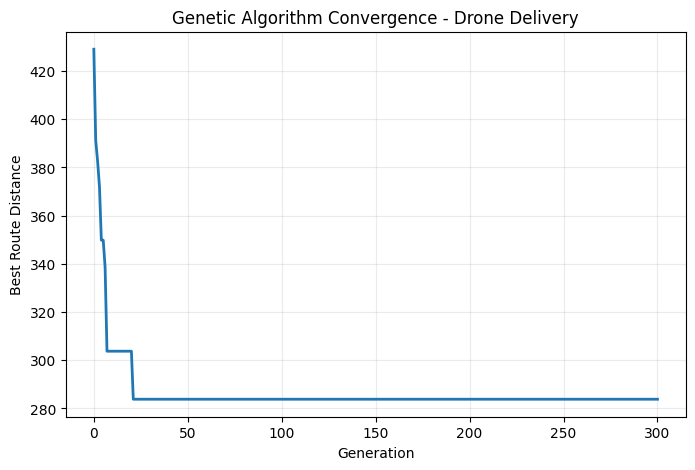

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history,
    linewidth=2
)

plt.title(
    "Genetic Algorithm Convergence - Drone Delivery"
)

plt.xlabel("Generation")
plt.ylabel("Best Route Distance")

plt.grid(alpha=0.25)
plt.show()

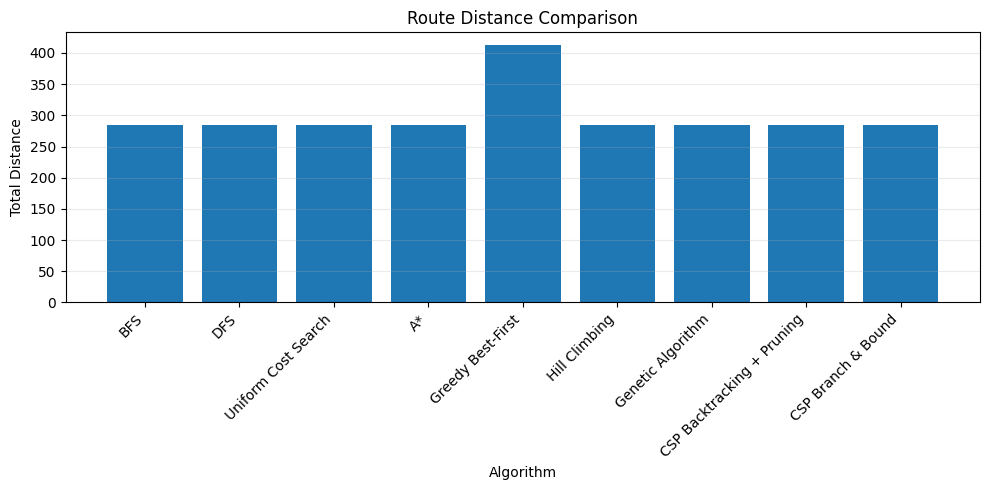

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["Distance"]
)

plt.title(
    "Route Distance Comparison"
)

plt.xlabel("Algorithm")
plt.ylabel("Total Distance")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

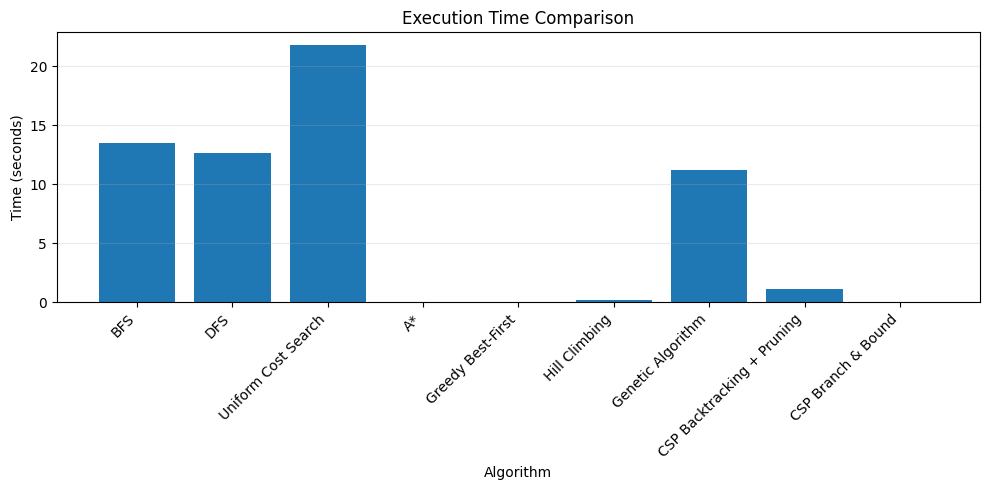

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["Time (s)"]
)

plt.title(
    "Execution Time Comparison"
)

plt.xlabel("Algorithm")
plt.ylabel("Time (seconds)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [ ]:
print("""
1. BFS, DFS, UCS, A*, Hill Climbing, GA and CSP found the shortest route of 283.84 km.
2. Greedy Best-First produced 412.37 km with a 45.283% optimality gap.
3. BFS, DFS and UCS expanded 986410 states each.
4. A* expanded 16 states, while CSP Branch & Bound expanded 79 states.
5. Hill Climbing used 177 iterations and 30 restarts, while GA used 300 generations.
6. A* and CSP Branch & Bound had very low execution times.
7. BFS used the highest peak memory of approximately 75.251 MB.
8. CSP methods use constraints, while Branch & Bound adds cost-based pruning.
9. Overall, informed and constraint-based methods reduce unnecessary search effort.
""")


1. BFS, DFS, UCS, A*, Hill Climbing, GA and CSP found the shortest route of 283.84 km.
2. Greedy Best-First produced 412.37 km with a 45.283% optimality gap.
3. BFS, DFS and UCS expanded 986410 states each.
4. A* expanded 16 states, while CSP Branch & Bound expanded 79 states.
5. Hill Climbing used 177 iterations and 30 restarts, while GA used 300 generations.
6. A* and CSP Branch & Bound had very low execution times.
7. BFS used the highest peak memory of approximately 75.251 MB.
8. CSP methods use constraints, while Branch & Bound adds cost-based pruning.
9. Overall, informed and constraint-based methods reduce unnecessary search effort.

